# Head Pose Estimation: fine-tuning 6DRepNet360 on AFLW2000-3D

## 1. Imports

In [1]:
import copy
import dataclasses
import hashlib
import json
import math
import os
import pickle
import random
import tempfile
import time
import zipfile
from collections.abc import Sequence
from concurrent.futures import ThreadPoolExecutor
from dataclasses import dataclass
from pathlib import Path
from typing import NamedTuple, Optional

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from IPython.display import display
from PIL import Image, ImageOps
from scipy.io import loadmat
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms as T
from tqdm.auto import tqdm

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", DEVICE, "| torch", torch.__version__, "| torchvision", torchvision.__version__)

device: cuda | torch 2.11.0+cu130 | torchvision 0.26.0+cu130


## 2. Configuration

In [2]:
ANGLE_NAMES = ("pitch", "yaw", "roll")  # order stored in the AFLW2000 / 300W-LP Pose_Para

WEIGHTS_URL = "https://cloud.ovgu.de/s/TewGC9TDLGgKkmS/download/6DRepNet360_Full-Rotation_300W_LP+Panoptic.pth"
WEIGHTS_FILE = "6DRepNet360_Full-Rotation_300W_LP+Panoptic.pth"

# Preprocessing, copied from the official test.py and AFLW2000 loader
RESIZE_SIDE, CROP_SIDE = 256, 224   # Resize(256) + CenterCrop(224); the network needs a 7x7 final feature map
K_EVAL = 0.20                       # official AFLW2000 crop margin factor
TRAIN_K_RANGE = (0.15, 0.30)        # random margin factor in training (crop-style jitter)

# Data validation
MIN_FACE_PX = 16.0                  # smaller landmark boxes are treated as bad annotations
MAX_BAD_FRACTION = 0.005            # abort if more than 0.5% of annotations are unusable
INDEX_THREADS = 16
SANITY_MAX_ZERO_SHOT_MAE = 15.0     # official weights should be far better than this; if not, something is mismatched

# Fine-tuning stages, deepest first: Phase.n_stages = how many of these train (0 = head only)
STAGES = (("layer4",), ("layer3",), ("layer2",), ("layer1",), ("conv1", "bn1"))


@dataclass(frozen=True)
class Phase:
    """One stage of partial fine-tuning."""
    epochs: int
    n_stages: int       # 0 = head only, 1 = + layer4, 2 = + layer3, ...
    lr_head: float
    lr_backbone: float

    def __post_init__(self):
        if self.epochs < 1 or not 0 <= self.n_stages <= len(STAGES):
            raise ValueError(f"invalid phase: {self}")
        if self.n_stages > 0 and self.lr_backbone <= 0:
            raise ValueError("lr_backbone must be > 0 when backbone stages are unfrozen")


# Untuned starting points (small LRs: the weights are already good and the data is small)
PHASES = (Phase(3, 0, 1e-4, 0.0), Phase(6, 1, 5e-5, 1e-5), Phase(6, 2, 2e-5, 5e-6))


@dataclass(frozen=True)
class Config:
    data_aflw2000: str
    work_dir: str
    run_name: str = "finetune"
    batch_size: int = 32
    num_workers: int = min(8, os.cpu_count() or 2)
    seed: int = 42
    val_fraction: float = 0.10
    test_fraction: float = 0.20
    max_abs_deg: Optional[float] = None   # e.g. 99.0 to mimic the common AFLW2000 protocol; None = keep all (official test.py)
    weight_decay: float = 1e-4
    grad_clip: float = 5.0
    deterministic: bool = True            # cudnn.deterministic; False = cudnn.benchmark (faster, not bit-reproducible)
    allow_unsafe_pickle: bool = False     # only for the official .pth if weights_only loading fails (see section 7)
    phases: tuple = PHASES

    def __post_init__(self):
        if not (0 < self.val_fraction and 0 < self.test_fraction and self.val_fraction + self.test_fraction < 1):
            raise ValueError("val_fraction and test_fraction must be > 0 and sum to < 1")

    @property
    def tag(self) -> str:
        return f"6drepnet360_{self.run_name}"

## 3. Data


In [3]:
from google.colab import drive

drive.mount("/content/drive")

DATA_ROOT = Path("/content/data")
WORK_DIR = Path("/content/drive/MyDrive/cos30082_hpe")
ZIP_AFLW2000 = Path("/content/drive/MyDrive/datasets/AFLW2000-3D.zip")   # <- edit

WORK_DIR.mkdir(parents=True, exist_ok=True)


def extract_once(zip_path: Path, dest: Path) -> None:
    if not zip_path.exists():
        raise FileNotFoundError(f"zip not found: {zip_path}")
    marker = dest / f".extracted_{zip_path.stem}"
    if marker.exists():
        return
    dest.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(zip_path) as zf:
        zf.extractall(dest)
    marker.touch()


def find_dir_containing(root: Path, name: str) -> Path:
    for dirpath, dirnames, filenames in os.walk(root):
        if name in dirnames or name in filenames:
            return Path(dirpath)
    raise FileNotFoundError(f"'{name}' not found under {root}")


extract_once(ZIP_AFLW2000, DATA_ROOT)
ROOT_AFLW2000 = find_dir_containing(DATA_ROOT, "image00002.jpg")
print("AFLW2000:", ROOT_AFLW2000, "| jpgs:", len(list(ROOT_AFLW2000.glob("*.jpg"))))

# Edit the knobs here (phases, batch size, split fractions, ...) and re-run from this cell.
cfg = Config(data_aflw2000=str(ROOT_AFLW2000), work_dir=str(WORK_DIR))
print(cfg.tag, "| phases:", [(p.epochs, p.n_stages, p.lr_head, p.lr_backbone) for p in cfg.phases])

Mounted at /content/drive
AFLW2000: /content/data/AFLW2000 | jpgs: 2000
6drepnet360_finetune | phases: [(3, 0, 0.0001, 0.0), (6, 1, 5e-05, 1e-05), (6, 2, 2e-05, 5e-06)]


## 4. Rotation maths and metrics


In [4]:
def euler_to_matrix_np(pitch: float, yaw: float, roll: float) -> np.ndarray:
    """R = Rz(roll) @ Ry(yaw) @ Rx(pitch); radians; float32 (3, 3). Same as the official get_R."""
    cx, sx = np.cos(pitch), np.sin(pitch)
    cy, sy = np.cos(yaw), np.sin(yaw)
    cz, sz = np.cos(roll), np.sin(roll)
    rx = np.array([[1, 0, 0], [0, cx, -sx], [0, sx, cx]])
    ry = np.array([[cy, 0, sy], [0, 1, 0], [-sy, 0, cy]])
    rz = np.array([[cz, -sz, 0], [sz, cz, 0], [0, 0, 1]])
    return (rz @ ry @ rx).astype(np.float32)


def rot6d_to_matrix(raw: torch.Tensor) -> torch.Tensor:
    """(B, 6) -> (B, 3, 3) rotation matrices (columns x, y, z); same Gram-Schmidt as the official code."""
    raw = raw.float()
    x = F.normalize(raw[:, 0:3], dim=1)
    z = F.normalize(torch.cross(x, raw[:, 3:6], dim=1), dim=1)
    y = torch.cross(z, x, dim=1)
    return torch.stack((x, y, z), dim=2)


def matrix_to_euler(rot: torch.Tensor) -> torch.Tensor:
    """(B, 3, 3) -> (B, 3) radians in (pitch, yaw, roll); same as the official compute_euler_angles_from_rotation_matrices."""
    sy = torch.sqrt(rot[:, 0, 0] ** 2 + rot[:, 1, 0] ** 2)
    singular = sy < 1e-6
    pitch = torch.atan2(rot[:, 2, 1], rot[:, 2, 2])
    yaw = torch.atan2(-rot[:, 2, 0], sy)
    roll = torch.atan2(rot[:, 1, 0], rot[:, 0, 0])
    pitch = torch.where(singular, torch.atan2(-rot[:, 1, 2], rot[:, 1, 1]), pitch)
    roll = torch.where(singular, torch.zeros_like(roll), roll)
    return torch.stack((pitch, yaw, roll), dim=1)


def geodesic_loss(pred: torch.Tensor, target: torch.Tensor, eps: float = 1e-7) -> torch.Tensor:
    """Mean geodesic distance (radians) between batches of rotation matrices."""
    rel = pred @ target.transpose(1, 2)
    cos = (rel.diagonal(dim1=1, dim2=2).sum(-1) - 1.0) / 2.0
    return torch.acos(cos.clamp(-1.0 + eps, 1.0 - eps)).mean()


def angle_diff_deg(pred_rad: torch.Tensor, gt_rad: torch.Tensor) -> torch.Tensor:
    """Absolute angular difference in degrees, wrapped to [0, 180]."""
    diff = (pred_rad - gt_rad) * 180.0 / math.pi
    return ((diff + 180.0) % 360.0 - 180.0).abs()


def row_angle_error_deg(rot_pred: torch.Tensor, rot_gt: torch.Tensor) -> torch.Tensor:
    """(B, 3): angle in degrees between the i-th rows of predicted and ground-truth matrices (official 'vector error')."""
    cos = (rot_pred * rot_gt).sum(-1).clamp(-1.0, 1.0)
    return torch.acos(cos) * 180.0 / math.pi


def draw_axis(
    img: np.ndarray, yaw: float, pitch: float, roll: float,
    cx: Optional[float] = None, cy: Optional[float] = None, size: int = 80,
) -> np.ndarray:
    """Draw the head's X (red), Y (green), Z (blue) axes; angles in degrees (same formula as the official draw_axis)."""
    pitch, yaw, roll = (math.radians(pitch), -math.radians(yaw), math.radians(roll))
    h, w = img.shape[:2]
    cx = w / 2 if cx is None else cx
    cy = h / 2 if cy is None else cy
    x1 = size * (math.cos(yaw) * math.cos(roll)) + cx
    y1 = size * (math.cos(pitch) * math.sin(roll) + math.cos(roll) * math.sin(pitch) * math.sin(yaw)) + cy
    x2 = size * (-math.cos(yaw) * math.sin(roll)) + cx
    y2 = size * (math.cos(pitch) * math.cos(roll) - math.sin(pitch) * math.sin(yaw) * math.sin(roll)) + cy
    x3 = size * math.sin(yaw) + cx
    y3 = size * (-math.cos(yaw) * math.sin(pitch)) + cy
    out = img.copy()
    for (x, y), color in (((x1, y1), (255, 0, 0)), ((x2, y2), (0, 255, 0)), ((x3, y3), (0, 0, 255))):
        cv2.line(out, (int(cx), int(cy)), (int(x), int(y)), color, 3)
    return out

## 5. Dataset

In [5]:
def _read_annotation(mat_path: Path) -> tuple[np.ndarray, np.ndarray]:
    """Return (pitch/yaw/roll in radians, landmark box x0,y0,x1,y1); raises ValueError on bad data."""
    mat = loadmat(str(mat_path), variable_names=["Pose_Para", "pt2d"])
    pose = np.asarray(mat["Pose_Para"]).reshape(-1)[:3].astype(np.float32)  # pitch, yaw, roll (rad)
    pts = np.asarray(mat["pt2d"], dtype=np.float32)
    bbox = np.array([pts[0].min(), pts[1].min(), pts[0].max(), pts[1].max()], dtype=np.float32)
    if pose.shape != (3,) or not (np.isfinite(pose).all() and np.isfinite(bbox).all()):
        raise ValueError("non-finite or malformed pose / landmarks")
    if max(bbox[2] - bbox[0], bbox[3] - bbox[1]) < MIN_FACE_PX:
        raise ValueError("degenerate landmark box")
    return pose, bbox


def _safe_read(jpg: Path) -> tuple[Optional[tuple[np.ndarray, np.ndarray]], Optional[str]]:
    """Return (annotation, None) or (None, reason). Only expected data errors are caught."""
    try:
        return _read_annotation(jpg.with_suffix(".mat")), None
    except (OSError, KeyError, ValueError, NotImplementedError) as exc:
        return None, f"{jpg.name}: {type(exc).__name__}: {exc}"


def build_index(root: Path, subfolders: Sequence[str], cache_path: Path) -> dict:
    """Return {"paths": (N,), "poses": (N, 3), "bboxes": (N, 4)}; cached on disk."""
    if cache_path.exists():
        data = np.load(cache_path, allow_pickle=False)
        return {k: data[k] for k in data.files}
    jpgs = sorted(p for sub in subfolders for p in (root / sub).glob("*.jpg"))
    if not jpgs:
        raise FileNotFoundError(f"no jpg files under {root} / {list(subfolders)}")
    with ThreadPoolExecutor(max_workers=INDEX_THREADS) as pool:
        results = list(tqdm(pool.map(_safe_read, jpgs), total=len(jpgs), desc=f"index {root.name}"))
    errors = [err for _, err in results if err is not None]
    if len(errors) > MAX_BAD_FRACTION * len(jpgs):
        raise RuntimeError(f"{len(errors)}/{len(jpgs)} annotations unusable under {root}, e.g. {errors[:3]}")
    if errors:
        print(f"skipped {len(errors)} bad annotations, e.g. {errors[:2]}")
    keep = [(p, ann) for p, (ann, err) in zip(jpgs, results, strict=True) if err is None]
    print(f"{len(keep)}/{len(jpgs)} usable samples")
    index = {
        "paths": np.array([str(p) for p, _ in keep]),
        "poses": np.stack([r[0] for _, r in keep]),
        "bboxes": np.stack([r[1] for _, r in keep]),
    }
    np.savez(cache_path, **index)
    return index


def select(index: dict, selector: np.ndarray) -> dict:
    return {k: v[selector] for k, v in index.items()}


def filter_by_angle(index: dict, max_abs_deg: Optional[float]) -> dict:
    if max_abs_deg is None:
        return index
    ok = (np.abs(np.degrees(index["poses"])) <= max_abs_deg).all(axis=1)
    return select(index, ok)


def split_index(index: dict, val_fraction: float, test_fraction: float, seed: int) -> tuple[dict, dict, dict]:
    """Random image-level split -> (train, val, test); disjoint, deterministic for a given seed."""
    n = len(index["paths"])
    order = np.random.default_rng(seed).permutation(n)
    n_test, n_val = round(n * test_fraction), round(n * val_fraction)
    parts = (order[n_test + n_val:], order[n_test:n_test + n_val], order[:n_test])  # train, val, test
    if min(len(p) for p in parts) == 0:
        raise ValueError(f"split of {n} samples left an empty part")
    return tuple(select(index, np.sort(ids)) for ids in parts)


def crop_like_6drepnet(img: Image.Image, bbox: Sequence[float], k: float = K_EVAL) -> Image.Image:
    """The official AFLW2000 crop: asymmetric margins; right/bottom use the already-widened box (as in the repo)."""
    x0, y0, x1, y1 = (float(v) for v in bbox)
    x0 -= 2 * k * abs(x1 - x0)
    y0 -= 2 * k * abs(y1 - y0)
    x1 += 2 * k * abs(x1 - x0)
    y1 += 0.6 * k * abs(y1 - y0)
    return img.crop((int(x0), int(y0), int(x1), int(y1)))


class PoseDataset(Dataset):
    """Returns (image in [0, 1], rotation matrix, euler (pitch, yaw, roll) in radians)."""

    def __init__(self, index: dict, train: bool):
        self.paths, self.poses, self.bboxes = index["paths"], index["poses"], index["bboxes"]
        self.train = train
        self.color = T.Compose([
            T.ColorJitter(0.3, 0.3, 0.3, 0.03),
            T.RandomApply([T.GaussianBlur(5, (0.1, 1.5))], p=0.05),
        ])
        self.resize = T.Resize(RESIZE_SIDE)
        self.crop = T.RandomCrop(CROP_SIDE) if train else T.CenterCrop(CROP_SIDE)

    def __len__(self) -> int:
        return len(self.paths)

    def __getitem__(self, i: int) -> tuple[torch.Tensor, torch.Tensor, torch.Tensor]:
        img = Image.open(self.paths[i]).convert("RGB")
        pitch, yaw, roll = (float(v) for v in self.poses[i])
        x0, y0, x1, y1 = (float(v) for v in self.bboxes[i])
        k = K_EVAL
        if self.train:
            if random.random() < 0.5:  # mirror: yaw and roll change sign, pitch is unchanged
                img = ImageOps.mirror(img)
                x0, x1 = img.width - x1, img.width - x0
                yaw, roll = -yaw, -roll
            k = random.uniform(*TRAIN_K_RANGE)
        face = crop_like_6drepnet(img, (x0, y0, x1, y1), k)
        if self.train:
            face = self.color(face)
        tensor = T.functional.to_tensor(self.crop(self.resize(face)))
        euler = np.array([pitch, yaw, roll], dtype=np.float32)
        return tensor, torch.from_numpy(euler_to_matrix_np(pitch, yaw, roll)), torch.from_numpy(euler)

## 6. Visual label check

AFLW2000 split: train 1400 | val 200 | test 400


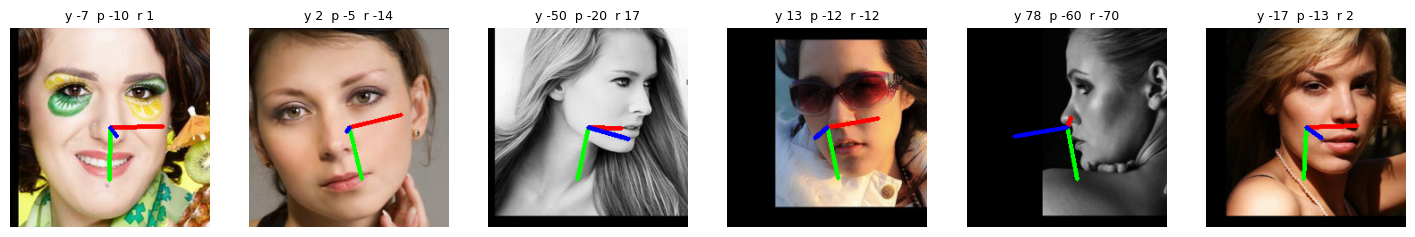

In [6]:
aflw_index = filter_by_angle(build_index(ROOT_AFLW2000, [""], WORK_DIR / "index_aflw2000.npz"), cfg.max_abs_deg)
train_index, val_index, test_index = split_index(aflw_index, cfg.val_fraction, cfg.test_fraction, cfg.seed)
print(f"AFLW2000 split: train {len(train_index['paths'])} | val {len(val_index['paths'])} | test {len(test_index['paths'])}")

check_ds = PoseDataset(test_index, train=False)
picks = np.random.default_rng(0).choice(len(check_ds), 6, replace=False)
fig, axes = plt.subplots(1, 6, figsize=(18, 3.4))
for ax, i in zip(axes, picks, strict=True):
    tensor, _, euler = check_ds[int(i)]
    pitch, yaw, roll = np.degrees(euler.numpy())
    frame = (tensor.permute(1, 2, 0).numpy() * 255).astype(np.uint8)
    ax.imshow(draw_axis(frame, yaw, pitch, roll, size=60))
    ax.set_title(f"y {yaw:.0f}  p {pitch:.0f}  r {roll:.0f}", fontsize=9)
    ax.axis("off")
plt.show()

## 7. Model: official layout, pretrained weights, evaluation


In [7]:
IMAGENET_STATS = ((0.485, 0.456, 0.406), (0.229, 0.224, 0.225))


class SixDRepNet360(nn.Module):
    """ResNet-50 + Linear(2048, 6), layout identical to the official 6DRepNet360 checkpoint (input 224 x 224)."""

    def __init__(self) -> None:
        super().__init__()
        net = torchvision.models.resnet50(weights=None)
        self.conv1, self.bn1, self.relu, self.maxpool = net.conv1, net.bn1, net.relu, net.maxpool
        self.layer1, self.layer2, self.layer3, self.layer4 = net.layer1, net.layer2, net.layer3, net.layer4
        self.avgpool = nn.AvgPool2d(7)
        self.linear_reg = nn.Linear(512 * 4, 6)
        self.register_buffer("mean", torch.tensor(IMAGENET_STATS[0]).view(1, 3, 1, 1), persistent=False)
        self.register_buffer("std", torch.tensor(IMAGENET_STATS[1]).view(1, 3, 1, 1), persistent=False)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """x: RGB in [0, 1], (B, 3, 224, 224) -> rotation matrices (B, 3, 3), float32."""
        x = (x - self.mean) / self.std
        x = self.maxpool(self.relu(self.bn1(self.conv1(x))))
        x = self.layer4(self.layer3(self.layer2(self.layer1(x))))
        return rot6d_to_matrix(self.linear_reg(self.avgpool(x).flatten(1)))


def load_pretrained(model: SixDRepNet360, cache_dir: Path, allow_unsafe_pickle: bool = False) -> str:
    """Load the official Full-Rotation checkpoint strictly; return its SHA-256."""
    cache_dir.mkdir(parents=True, exist_ok=True)
    try:
        state = torch.hub.load_state_dict_from_url(
            WEIGHTS_URL, model_dir=str(cache_dir), map_location="cpu", file_name=WEIGHTS_FILE,
            weights_only=not allow_unsafe_pickle,
        )
    except pickle.UnpicklingError as exc:
        raise RuntimeError(
            "weights_only loading rejected the official checkpoint. If you trust the file from the authors' "
            "release, set allow_unsafe_pickle=True in Config and compare the printed SHA-256 with your report."
        ) from exc
    model.load_state_dict(state.get("model_state_dict", state), strict=True)
    return hashlib.sha256((cache_dir / WEIGHTS_FILE).read_bytes()).hexdigest()


def count_params(model: nn.Module, trainable_only: bool = False) -> int:
    return sum(p.numel() for p in model.parameters() if p.requires_grad or not trainable_only)


def set_trainable(model: SixDRepNet360, n_stages: int) -> None:
    """Head always trains; the `n_stages` deepest ResNet stages train; everything else is frozen."""
    for p in model.parameters():
        p.requires_grad_(False)
    for p in model.linear_reg.parameters():
        p.requires_grad_(True)
    for names in STAGES[:n_stages]:
        for name in names:
            for p in getattr(model, name).parameters():
                p.requires_grad_(True)


def freeze_bn_stats_of_frozen_layers(model: nn.Module) -> None:
    """Keep running statistics fixed in BatchNorm layers whose parameters are frozen."""
    batchnorm = nn.modules.batchnorm._BatchNorm
    for module in model.modules():
        if isinstance(module, batchnorm) and not any(p.requires_grad for p in module.parameters()):
            module.eval()


@torch.inference_mode()
def evaluate(model: nn.Module, loader: DataLoader, device: torch.device) -> dict:
    """MAE (deg, wrap-aware) per angle and mean, plus the official vector error (VMAE)."""
    model.eval()
    abs_err, vec_err = [], []
    for imgs, rot_gt, euler_gt in loader:
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=device.type == "cuda"):
            rot_pred = model(imgs.to(device, non_blocking=True))
        rot_pred = rot_pred.float().cpu()
        abs_err.append(angle_diff_deg(matrix_to_euler(rot_pred), euler_gt))
        vec_err.append(row_angle_error_deg(rot_pred, rot_gt))
    mae = torch.cat(abs_err).mean(dim=0)
    out = {f"mae_{name}": mae[i].item() for i, name in enumerate(ANGLE_NAMES)}
    out["mae_mean"] = mae.mean().item()
    out["vmae"] = torch.cat(vec_err).mean().item()
    return out

### Tests

In [8]:
def _write_sample(folder: Path, name: str, pts: np.ndarray) -> None:
    from scipy.io import savemat

    Image.new("RGB", (32, 32)).save(folder / f"{name}.jpg")
    savemat(folder / f"{name}.mat", {"Pose_Para": np.array([[0.1, 0.2, 0.3, 0, 0, 0, 1.0]]), "pt2d": pts})


def test_rotation_maths() -> None:
    eye = torch.eye(3).expand(8, 3, 3)
    rot = rot6d_to_matrix(torch.randn(8, 6))
    assert torch.allclose(rot @ rot.transpose(1, 2), eye, atol=1e-5), "not orthonormal"
    assert torch.allclose(torch.linalg.det(rot), torch.ones(8), atol=1e-5), "det != 1"

    angles = np.random.default_rng(0).uniform(-1.2, 1.2, size=(16, 3)).astype(np.float32)
    mats = torch.from_numpy(np.stack([euler_to_matrix_np(*a) for a in angles]))
    assert torch.allclose(matrix_to_euler(mats), torch.from_numpy(angles), atol=1e-4), "euler round trip"

    quarter = torch.from_numpy(euler_to_matrix_np(0.0, 0.0, math.pi / 2))[None]
    assert geodesic_loss(eye[:1].clone(), eye[:1].clone()).item() < 1e-3
    assert abs(geodesic_loss(quarter, eye[:1].clone()).item() - math.pi / 2) < 1e-3

    s = np.diag([-1.0, 1.0, 1.0]).astype(np.float32)  # mirror == (pitch, -yaw, -roll)
    p, y, r = 0.3, 0.7, -0.4
    assert np.allclose(s @ euler_to_matrix_np(p, y, r) @ s, euler_to_matrix_np(p, -y, -r), atol=1e-5), "flip rule"


def test_angle_metrics() -> None:
    near_pi = torch.tensor([[math.radians(179.0), 0.0, 0.0]])
    assert abs(angle_diff_deg(near_pi, -near_pi).max().item() - 2.0) < 1e-3, "wrap-around: 179 vs -179 is 2 degrees"
    rot_gt = torch.from_numpy(euler_to_matrix_np(0.2, 0.4, 0.6))[None]
    assert row_angle_error_deg(rot_gt, rot_gt).abs().max().item() < 0.1, "identical rotations must have ~0 vector error"


def test_crop_matches_official_recipe() -> None:
    # hand-computed from the official AFLW2000 loader for bbox (100, 100, 200, 200), k = 0.2:
    # x0 = 100 - 40 = 60, y0 = 60, x1 = 200 + 0.4 * |200 - 60| = 256, y1 = 200 + 0.12 * |200 - 60| = 216.8
    crop = crop_like_6drepnet(Image.new("RGB", (400, 400)), (100, 100, 200, 200), k=0.2)
    assert crop.size == (256 - 60, 216 - 60), crop.size


def test_split_is_disjoint_and_deterministic() -> None:
    n = 100
    index = {"paths": np.array([f"/x/image{i:05d}.jpg" for i in range(n)]),
             "poses": np.zeros((n, 3), np.float32), "bboxes": np.zeros((n, 4), np.float32)}
    train, val, test = split_index(index, 0.10, 0.20, seed=0)
    sets = [set(part["paths"]) for part in (train, val, test)]
    assert (len(train["paths"]), len(val["paths"]), len(test["paths"])) == (70, 10, 20)
    assert not (sets[0] & sets[1] or sets[0] & sets[2] or sets[1] & sets[2]), "splits overlap"
    assert set(split_index(index, 0.10, 0.20, seed=0)[2]["paths"]) == sets[2], "split must be deterministic"


def test_dataset_item() -> None:
    with tempfile.TemporaryDirectory() as tmp:
        path = Path(tmp) / "image00001.jpg"
        Image.fromarray(np.random.default_rng(0).integers(0, 255, (300, 300, 3), dtype=np.uint8)).save(path)
        pose = np.array([[0.1, 0.5, -0.2]], np.float32)
        index = {"paths": np.array([str(path)]), "poses": pose, "bboxes": np.array([[100, 100, 200, 200]], np.float32)}
        for train in (False, True):
            img, rot, euler = PoseDataset(index, train=train)[0]
            assert img.shape == (3, CROP_SIDE, CROP_SIDE) and img.min() >= 0.0 and img.max() <= 1.0
            assert torch.allclose(rot, torch.from_numpy(euler_to_matrix_np(*euler.tolist())), atol=1e-5), "rot != euler"
            if not train:
                assert np.allclose(euler.numpy(), pose[0]), "eval samples must not be augmented"


def test_build_index_validation() -> None:
    good = np.array([[5.0, 25.0], [5.0, 25.0]])   # 20 px box
    nan_pts = np.full((2, 2), np.nan)              # corrupt landmarks
    tiny = np.array([[10.0, 11.0], [10.0, 11.0]])  # 1 px box
    with tempfile.TemporaryDirectory() as tmp:
        folder = Path(tmp) / "mostly_good"
        folder.mkdir()
        for i in range(250):
            _write_sample(folder, f"s{i:03d}", good)
        _write_sample(folder, "bad_nan", nan_pts)
        index = build_index(folder, [""], Path(tmp) / "a.npz")
        assert len(index["paths"]) == 250 and np.isfinite(index["bboxes"]).all()

        folder = Path(tmp) / "mostly_bad"
        folder.mkdir()
        for name, pts in (("g1", good), ("g2", good), ("b1", nan_pts), ("b2", tiny)):
            _write_sample(folder, name, pts)
        try:
            build_index(folder, [""], Path(tmp) / "b.npz")
        except RuntimeError as exc:
            assert "unusable" in str(exc)
        else:
            raise AssertionError("build_index accepted a mostly-bad dataset")


def test_model_layout_and_freezing() -> None:
    model = SixDRepNet360()
    keys = set(model.state_dict())
    assert {"conv1.weight", "layer4.2.conv3.weight", "linear_reg.weight", "linear_reg.bias"} <= keys
    assert not any(k.startswith(("fc.", "mean", "std")) for k in keys), "state dict must match the official layout"
    assert 23.4e6 < count_params(model) < 23.6e6, count_params(model)

    rot = model.eval()(torch.rand(2, 3, CROP_SIDE, CROP_SIDE))
    assert rot.shape == (2, 3, 3) and torch.allclose(rot @ rot.transpose(1, 2), torch.eye(3).expand(2, 3, 3), atol=1e-4)

    set_trainable(model, 0)
    assert {n for n, p in model.named_parameters() if p.requires_grad} == {"linear_reg.weight", "linear_reg.bias"}
    set_trainable(model, 1)
    names = {n.split(".")[0] for n, p in model.named_parameters() if p.requires_grad}
    assert names == {"layer4", "linear_reg"}, names
    set_trainable(model, len(STAGES))
    assert all(p.requires_grad for p in model.parameters())

    set_trainable(model, 1)  # BN statistics: frozen stages stay in eval mode, trainable ones in train mode
    model.train()
    freeze_bn_stats_of_frozen_layers(model)
    assert not model.layer1[0].bn1.training and model.layer4[0].bn1.training


class _IdentityModel(nn.Module):
    """Always predicts 'facing the camera' (identity rotation)."""

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return torch.eye(3).expand(x.size(0), 3, 3).clone()


def test_evaluate_arithmetic() -> None:
    n, gt_deg = 8, (10.0, 20.0, 30.0)  # pitch, yaw, roll
    euler = torch.tensor([gt_deg]).repeat(n, 1) * math.pi / 180
    rot = torch.from_numpy(np.stack([euler_to_matrix_np(*e) for e in euler.tolist()]))
    data = torch.utils.data.TensorDataset(torch.rand(n, 3, 8, 8), rot, euler)
    mae = evaluate(_IdentityModel(), DataLoader(data, batch_size=4), torch.device("cpu"))
    assert abs(mae["mae_pitch"] - 10) < 1e-3 and abs(mae["mae_yaw"] - 20) < 1e-3 and abs(mae["mae_roll"] - 30) < 1e-3
    expected_vmae = np.mean([math.degrees(math.acos(rot[0, i, i].item())) for i in range(3)])
    assert abs(mae["vmae"] - expected_vmae) < 1e-2, (mae["vmae"], expected_vmae)


def test_training_step_learns() -> None:
    torch.manual_seed(0)
    model = SixDRepNet360().to(DEVICE).train()
    x = torch.rand(4, 3, CROP_SIDE, CROP_SIDE, device=DEVICE)
    angles = np.random.default_rng(1).uniform(-1.0, 1.0, (4, 3))
    target = torch.from_numpy(np.stack([euler_to_matrix_np(*a) for a in angles])).to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3)
    losses = []
    for _ in range(40):
        loss = geodesic_loss(model(x), target)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        losses.append(loss.item())
    assert losses[-1] < 0.8 * losses[0], f"loss did not drop: {losses[0]:.3f} -> {losses[-1]:.3f}"


def run_sanity_checks() -> None:
    for test in (test_rotation_maths, test_angle_metrics, test_crop_matches_official_recipe,
                 test_split_is_disjoint_and_deterministic, test_dataset_item, test_build_index_validation,
                 test_model_layout_and_freezing, test_evaluate_arithmetic, test_training_step_learns):
        test()
        print("ok  ", test.__name__)


run_sanity_checks()

ok   test_rotation_maths
ok   test_angle_metrics
ok   test_crop_matches_official_recipe
ok   test_split_is_disjoint_and_deterministic
ok   test_dataset_item


index mostly_good:   0%|          | 0/251 [00:00<?, ?it/s]

skipped 1 bad annotations, e.g. ['bad_nan.jpg: ValueError: non-finite or malformed pose / landmarks']
250/251 usable samples


index mostly_bad:   0%|          | 0/4 [00:00<?, ?it/s]

ok   test_build_index_validation
ok   test_model_layout_and_freezing
ok   test_evaluate_arithmetic
ok   test_training_step_learns


## 8. Fine-tuning

In [9]:
def seed_everything(seed: int, deterministic: bool = True) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = deterministic
    torch.backends.cudnn.benchmark = not deterministic


def make_loaders(cfg: Config) -> tuple[DataLoader, DataLoader, DataLoader]:
    work = Path(cfg.work_dir)
    index = filter_by_angle(build_index(Path(cfg.data_aflw2000), [""], work / "index_aflw2000.npz"), cfg.max_abs_deg)
    train, val, test = split_index(index, cfg.val_fraction, cfg.test_fraction, cfg.seed)
    print(f"train {len(train['paths'])} | val {len(val['paths'])} | test {len(test['paths'])}")
    manifest = {name: sorted(Path(p).stem for p in part["paths"]) for name, part in (("train", train), ("val", val), ("test", test))}
    (work / "results").mkdir(parents=True, exist_ok=True)
    (work / "results" / f"{cfg.tag}_split.json").write_text(json.dumps(manifest))

    def loader(part: dict, is_train: bool) -> DataLoader:
        return DataLoader(
            PoseDataset(part, is_train), batch_size=cfg.batch_size if is_train else 64,
            shuffle=is_train, drop_last=is_train, num_workers=cfg.num_workers,
            pin_memory=DEVICE.type == "cuda", persistent_workers=cfg.num_workers > 0,
        )

    return loader(train, True), loader(val, False), loader(test, False)


class PhaseTools(NamedTuple):
    """Optimizer, LR schedule and AMP scaler for one training phase."""

    optimizer: torch.optim.Optimizer
    scheduler: torch.optim.lr_scheduler.LRScheduler
    scaler: torch.amp.GradScaler


def _make_phase_tools(
    model: SixDRepNet360, phase: Phase, cfg: Config, steps_per_epoch: int, scaler: torch.amp.GradScaler,
) -> PhaseTools:
    set_trainable(model, phase.n_stages)
    groups = [{"params": list(model.linear_reg.parameters()), "lr": phase.lr_head}]
    backbone = [p for n, p in model.named_parameters() if p.requires_grad and not n.startswith("linear_reg")]
    if backbone:
        groups.append({"params": backbone, "lr": phase.lr_backbone})
    optimizer = torch.optim.AdamW(groups, weight_decay=cfg.weight_decay)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=phase.epochs * steps_per_epoch)
    return PhaseTools(optimizer, scheduler, scaler)


def train_one_epoch(model: SixDRepNet360, loader: DataLoader, tools: PhaseTools, cfg: Config, device: torch.device) -> float:
    model.train()
    freeze_bn_stats_of_frozen_layers(model)
    params = [p for group in tools.optimizer.param_groups for p in group["params"]]
    total, count = torch.zeros((), device=device), 0  # loss stays on-device: no per-step GPU sync
    for imgs, rot, _ in tqdm(loader, leave=False, desc="train"):
        imgs, rot = imgs.to(device, non_blocking=True), rot.to(device)
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=device.type == "cuda"):
            pred = model(imgs)
        loss = geodesic_loss(pred.float(), rot)
        tools.optimizer.zero_grad(set_to_none=True)
        tools.scaler.scale(loss).backward()
        tools.scaler.unscale_(tools.optimizer)
        torch.nn.utils.clip_grad_norm_(params, cfg.grad_clip)
        tools.scaler.step(tools.optimizer)
        tools.scaler.update()
        tools.scheduler.step()
        total += loss.detach() * imgs.size(0)
        count += imgs.size(0)
    return (total / max(count, 1)).item()


@torch.inference_mode()
def benchmark_speed(model: nn.Module, device: torch.device, warmup: int = 10, iters: int = 50) -> float:
    """Milliseconds per single-image forward pass."""
    m = copy.deepcopy(model).to(device).eval()
    x = torch.rand(1, 3, CROP_SIDE, CROP_SIDE, device=device)
    for _ in range(warmup):
        m(x)
    if device.type == "cuda":
        torch.cuda.synchronize()
    start = time.perf_counter()
    for _ in range(iters):
        m(x)
    if device.type == "cuda":
        torch.cuda.synchronize()
    return (time.perf_counter() - start) / iters * 1000.0


def _atomic_save(obj: dict, path: Path) -> None:
    """Write via a temp file so a Colab disconnect mid-write can never leave a corrupt checkpoint."""
    tmp = path.with_name(path.name + ".tmp")
    torch.save(obj, tmp)
    tmp.replace(path)


def _format_epoch(record: dict, improved: bool, seconds: float) -> str:
    return (f"epoch {record['epoch']:02d} | loss {record['train_loss']:.4f} | val MAE {record['val_mae_mean']:.2f} deg "
            f"(pitch {record['val_mae_pitch']:.2f} yaw {record['val_mae_yaw']:.2f} roll {record['val_mae_roll']:.2f})"
            f"{'  *best*' if improved else ''} | {seconds:.0f}s")


def _finalize(
    cfg: Config, model: SixDRepNet360, test_loader: DataLoader, ckpt_path: Path,
    baseline: dict, sha256: str, best: float, history: list,
) -> dict:
    """Reload the best checkpoint, run the single held-out test evaluation + speed benchmark, write results."""
    work = Path(cfg.work_dir)
    model.load_state_dict(torch.load(ckpt_path, map_location=DEVICE, weights_only=True)["model"])
    test = evaluate(model, test_loader, DEVICE)
    result = {
        "run": cfg.tag, "params_M": count_params(model) / 1e6, "pretrained_sha256": sha256,
        "epochs": len(history), "best_val_mae": best,
        **{f"zero_shot_{split}_{k}": v for split, d in baseline.items() for k, v in d.items()},
        **{f"test_{k}": v for k, v in test.items()},
        "ms_cpu": benchmark_speed(model, torch.device("cpu"), warmup=2, iters=10),
        "versions": {"torch": torch.__version__, "torchvision": torchvision.__version__},
    }
    if DEVICE.type == "cuda":
        result["ms_gpu"] = benchmark_speed(model, DEVICE)
    (work / "results" / f"{cfg.tag}_result.json").write_text(json.dumps(result, indent=2))
    (work / "results" / f"{cfg.tag}_history.json").write_text(json.dumps(history, indent=2))
    print(f"held-out test MAE: zero-shot {baseline['test']['mae_mean']:.2f} deg -> fine-tuned {test['mae_mean']:.2f} deg "
          f"(pitch {test['mae_pitch']:.2f} yaw {test['mae_yaw']:.2f} roll {test['mae_roll']:.2f} | VMAE {test['vmae']:.2f})")
    return result


def run_experiment(cfg: Config) -> tuple[dict, list]:
    seed_everything(cfg.seed, cfg.deterministic)
    work = Path(cfg.work_dir)
    for sub in ("checkpoints", "results"):
        (work / sub).mkdir(parents=True, exist_ok=True)
    ckpt_path = work / "checkpoints" / f"{cfg.tag}.pt"

    train_loader, val_loader, test_loader = make_loaders(cfg)
    model = SixDRepNet360()
    sha256 = load_pretrained(model, work / "weights", cfg.allow_unsafe_pickle)
    model.to(DEVICE)
    print(f"official checkpoint loaded (sha256 {sha256[:16]}...) | {count_params(model) / 1e6:.2f} M params")

    baseline = {"val": evaluate(model, val_loader, DEVICE), "test": evaluate(model, test_loader, DEVICE)}
    zero = baseline["test"]
    print(f"zero-shot, held-out test: MAE {zero['mae_mean']:.2f} deg "
          f"(pitch {zero['mae_pitch']:.2f} yaw {zero['mae_yaw']:.2f} roll {zero['mae_roll']:.2f} | VMAE {zero['vmae']:.2f})")
    if zero["mae_mean"] > SANITY_MAX_ZERO_SHOT_MAE:
        print("WARNING: zero-shot error is far above what the official weights should give; "
              "check the checkpoint, the crop recipe and the label convention before fine-tuning.")

    scaler = torch.amp.GradScaler(DEVICE.type, enabled=DEVICE.type == "cuda")
    best, history = float("inf"), []
    for phase_no, phase in enumerate(cfg.phases, start=1):
        tools = _make_phase_tools(model, phase, cfg, len(train_loader), scaler)
        print(f"-- phase {phase_no}: stages={phase.n_stages} trainable={count_params(model, True) / 1e6:.2f} M")
        for _ in range(phase.epochs):
            start = time.time()
            train_loss = train_one_epoch(model, train_loader, tools, cfg, DEVICE)
            val = evaluate(model, val_loader, DEVICE)
            record = {"epoch": len(history) + 1, "phase": phase_no, "train_loss": train_loss,
                      **{f"val_{k}": v for k, v in val.items()}}
            history.append(record)
            improved = val["mae_mean"] < best
            if improved:
                best = val["mae_mean"]
                _atomic_save({"model": model.state_dict(), "cfg": dataclasses.asdict(cfg), "val": val}, ckpt_path)
            print(_format_epoch(record, improved, time.time() - start))
    return _finalize(cfg, model, test_loader, ckpt_path, baseline, sha256, best, history), history

### Run

In [10]:
result, history = run_experiment(cfg)

train 1400 | val 200 | test 400
Downloading: "https://cloud.ovgu.de/s/TewGC9TDLGgKkmS/download/6DRepNet360_Full-Rotation_300W_LP+Panoptic.pth" to /content/drive/MyDrive/cos30082_hpe/weights/6DRepNet360_Full-Rotation_300W_LP+Panoptic.pth


100%|██████████| 90.0M/90.0M [00:07<00:00, 12.3MB/s]


official checkpoint loaded (sha256 3ee08f1e04b8d452...) | 23.52 M params
zero-shot, held-out test: MAE 4.79 deg (pitch 6.20 yaw 3.91 roll 4.25 | VMAE 5.14)
-- phase 1: stages=0 trainable=0.01 M


train:   0%|          | 0/43 [00:00<?, ?it/s]

/tmp/ipykernel_2116/785163245.py:66: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  tools.scheduler.step()


epoch 01 | loss 0.4638 | val MAE 5.36 deg (pitch 6.32 yaw 4.80 roll 4.96)  *best* | 38s


... (24 outputs left out)

train:   0%|          | 0/43 [00:00<?, ?it/s]

epoch 14 | loss 0.3086 | val MAE 5.68 deg (pitch 6.88 yaw 4.69 roll 5.46) | 37s


train:   0%|          | 0/43 [00:00<?, ?it/s]

epoch 15 | loss 0.2832 | val MAE 5.69 deg (pitch 6.86 yaw 4.74 roll 5.48) | 36s
held-out test MAE: zero-shot 4.79 deg -> fine-tuned 5.19 deg (pitch 6.37 yaw 4.16 roll 5.04 | VMAE 5.80)


## 9. Results: zero-shot vs fine-tuned

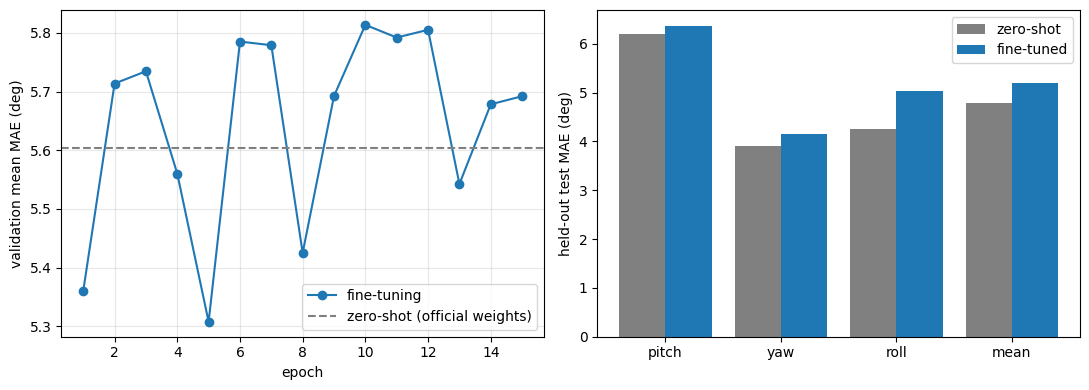

,zero-shot,fine-tuned
pitch MAE,6.199,6.371
yaw MAE,3.915,4.157
roll MAE,4.250,5.040
mean MAE,4.788,5.189
VMAE,5.137,5.796


params 23.5 M | CPU 2168 ms/img | GPU 6.9 ms/img
official checkpoint sha256: 3ee08f1e04b8d452a6c4a40926a6f38051894ae6d0aaa6d191fe6d8bc6e4f9c6


In [11]:
result = json.loads((WORK_DIR / "results" / f"{cfg.tag}_result.json").read_text())
history = json.loads((WORK_DIR / "results" / f"{cfg.tag}_history.json").read_text())

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.plot([h["epoch"] for h in history], [h["val_mae_mean"] for h in history], marker="o", label="fine-tuning")
ax1.axhline(result["zero_shot_val_mae_mean"], ls="--", color="gray", label="zero-shot (official weights)")
ax1.set_xlabel("epoch")
ax1.set_ylabel("validation mean MAE (deg)")
ax1.grid(alpha=0.3)
ax1.legend()

names = ["pitch", "yaw", "roll", "mean"]
before = [result[f"zero_shot_test_mae_{n}"] for n in names]
after = [result[f"test_mae_{n}"] for n in names]
x = np.arange(len(names))
ax2.bar(x - 0.2, before, 0.4, label="zero-shot", color="gray")
ax2.bar(x + 0.2, after, 0.4, label="fine-tuned")
ax2.set_xticks(x, names)
ax2.set_ylabel("held-out test MAE (deg)")
ax2.legend()
plt.tight_layout()
plt.show()

display(pd.DataFrame({
    "zero-shot": before + [result["zero_shot_test_vmae"]],
    "fine-tuned": after + [result["test_vmae"]],
}, index=["pitch MAE", "yaw MAE", "roll MAE", "mean MAE", "VMAE"]).round(3))
print(f"params {result['params_M']:.1f} M | CPU {result['ms_cpu']:.0f} ms/img" + (f" | GPU {result['ms_gpu']:.1f} ms/img" if "ms_gpu" in result else ""))
print("official checkpoint sha256:", result["pretrained_sha256"])

## 10. Inference module

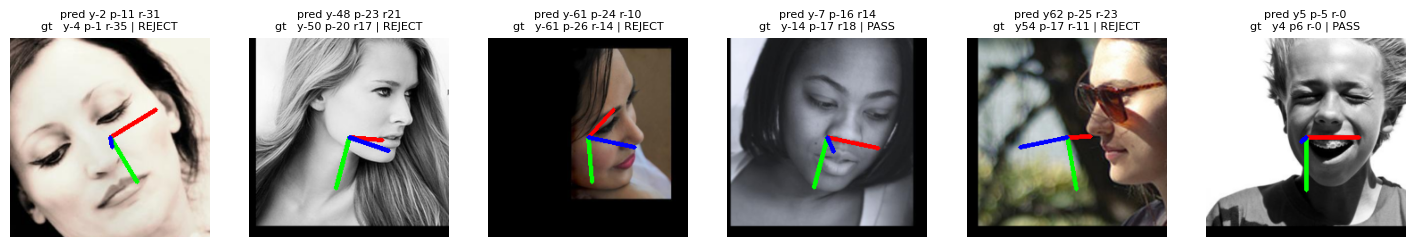

In [12]:
class HeadPoseEstimator:
    def __init__(self, ckpt_path, device: Optional[torch.device] = None):
        self.device = device or DEVICE
        ckpt = torch.load(ckpt_path, map_location="cpu", weights_only=True)
        self.model = SixDRepNet360()
        self.model.load_state_dict(ckpt["model"], strict=True)
        self.model.to(self.device).eval()
        self.resize, self.center = T.Resize(RESIZE_SIDE), T.CenterCrop(CROP_SIDE)

    @torch.inference_mode()
    def estimate(self, frame_rgb: np.ndarray, face_box: Sequence[float], k: float = K_EVAL) -> dict:
        if frame_rgb.ndim != 3 or frame_rgb.shape[2] != 3 or frame_rgb.dtype != np.uint8:
            raise ValueError(f"expected an RGB uint8 frame (H, W, 3), got shape {frame_rgb.shape} dtype {frame_rgb.dtype}")
        box = np.asarray(face_box, dtype=np.float64)
        if box.shape != (4,) or not np.isfinite(box).all() or max(box[2] - box[0], box[3] - box[1]) < MIN_FACE_PX:
            raise ValueError(f"invalid face box {face_box!r} (need finite x0,y0,x1,y1 with a side of at least {MIN_FACE_PX:.0f} px)")
        face = self.center(self.resize(crop_like_6drepnet(Image.fromarray(frame_rgb), box, k)))
        x = T.functional.to_tensor(face).unsqueeze(0).to(self.device)
        pitch, yaw, roll = (matrix_to_euler(self.model(x).float())[0].cpu() * 180.0 / math.pi).tolist()
        return {"yaw": yaw, "pitch": pitch, "roll": roll}


@dataclass(frozen=True)
class PoseGate:
    max_yaw: float = 25.0
    max_pitch: float = 20.0
    max_roll: float = 30.0

    def is_frontal(self, pose: dict) -> bool:
        return (abs(pose["yaw"]) <= self.max_yaw
                and abs(pose["pitch"]) <= self.max_pitch
                and abs(pose["roll"]) <= self.max_roll)


# demo
estimator = HeadPoseEstimator(WORK_DIR / "checkpoints" / f"{cfg.tag}.pt")
gate = PoseGate()
demo_picks = np.random.default_rng(1).choice(len(test_index["paths"]), 6, replace=False)
fig, axes = plt.subplots(1, 6, figsize=(18, 3.8))
for ax, i in zip(axes, demo_picks, strict=True):
    frame = np.asarray(Image.open(test_index["paths"][i]).convert("RGB"))
    pose = estimator.estimate(frame, test_index["bboxes"][i])
    gt = np.degrees(test_index["poses"][i])
    shown = np.asarray(T.CenterCrop(CROP_SIDE)(T.Resize(RESIZE_SIDE)(crop_like_6drepnet(Image.fromarray(frame), test_index["bboxes"][i]))))
    ax.imshow(draw_axis(shown, pose["yaw"], pose["pitch"], pose["roll"], size=60))
    ax.set_title(f"pred y{pose['yaw']:.0f} p{pose['pitch']:.0f} r{pose['roll']:.0f}\n"
                 f"gt   y{gt[1]:.0f} p{gt[0]:.0f} r{gt[2]:.0f} | {'PASS' if gate.is_frontal(pose) else 'REJECT'}", fontsize=8)
    ax.axis("off")
plt.show()

## 11. Save the trained model


In [13]:
def export_model(cfg: Config, out_dir: Optional[Path] = None) -> Path:
    """Write a weights-only inference checkpoint (model + config + metrics) and verify it reloads."""
    work = Path(cfg.work_dir)
    best_path = work / "checkpoints" / f"{cfg.tag}.pt"
    if not best_path.exists():
        raise FileNotFoundError(f"no trained checkpoint at {best_path}; run training first")
    ckpt = torch.load(best_path, map_location="cpu", weights_only=True)
    result_path = work / "results" / f"{cfg.tag}_result.json"
    metrics = json.loads(result_path.read_text()) if result_path.exists() else {}
    payload = {
        "model": ckpt["model"], "cfg": ckpt["cfg"], "val": ckpt["val"],
        "test": {k: v for k, v in metrics.items() if k.startswith(("test_", "zero_shot_"))},
    }
    out_dir = out_dir or work / "export"
    out_dir.mkdir(parents=True, exist_ok=True)
    out_path = out_dir / f"{cfg.tag}_inference.pt"
    _atomic_save(payload, out_path)

    saved = torch.load(out_path, map_location="cpu", weights_only=True)  # verify: strict reload + a forward pass
    check = SixDRepNet360().eval()
    check.load_state_dict(saved["model"], strict=True)
    with torch.no_grad():
        rot = check(torch.rand(1, 3, CROP_SIDE, CROP_SIDE))
    assert torch.allclose(rot @ rot.transpose(1, 2), torch.eye(3).expand(1, 3, 3), atol=1e-4), "invalid rotation output"
    test_mae = payload["test"].get("test_mae_mean", float("nan"))
    print(f"saved {out_path} ({out_path.stat().st_size / 1e6:.1f} MB) | held-out test MAE {test_mae:.2f} deg")
    return out_path


DOWNLOAD_TO_COMPUTER = True
EXPORT_PATH = export_model(cfg)
if DOWNLOAD_TO_COMPUTER:
    from google.colab import files

    files.download(str(EXPORT_PATH))

saved /content/drive/MyDrive/cos30082_hpe/export/6drepnet360_finetune_inference.pt (94.4 MB) | held-out test MAE 5.19 deg


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>